# The 1 May and 1 Aug 2026 forecasts with the trend-corrected drift (TrDC)

Eighth notebook of `nov2026_outlook/`. `07` chose the trend correction (TrDC: average drift plus a linear trend over
the start years, held at the last start, 2018) for the 1 Nov 2026 forecast, and `03` (section 3c) showed how that
forecast depends on the start years the trend is fitted on. This notebook applies the same correction to the two
earlier 2026 starts, **1 May** and **1 Aug** (30 pooled members each, 24 months: no year-3 extension).

| start | Reanalysis hindcast starts | trend slope | DJF winters in the forecast |
|---|---|---|---|
| 1 May 2026 | every year 1981-2018 (38) | May's own (T1), as Nov in `03` | 2026/27 (leads 7-9), 2027/28 (leads 19-21) |
| 1 Aug 2026 | every fifth year 1985-2015 (7) | pooled over the four start months (T1p of `04`); mean drift from Aug's own starts | 2026/27 (leads 4-6), 2027/28 (leads 16-18) |

Seven Aug starts are too few for a trend of their own (3-7 per window), so for Aug the slope at each lead is the
common slope of all four start months (Feb, May, Aug, Nov) in the window, fitted to the start-month-demeaned drift;
`04` found the year-2 drift trend positive for every start month (Aug +0.68, pooled +0.40 °C/decade). The
intercept stays Aug's own mean drift over its starts in the window.

Every correction is held at 2018 and fitted on start years ending in 2018: 1981-2018 (the `07` choice) and windows
starting 5 years later each time, as `03` section 3c. Anomalies from the observed 1991-2020 climatology. The observed
HadISST Niño3.4 anomaly of the months already observed is shown as a check. P(La Niña) is the fraction of the 30
members with a DJF mean ≤ −0.5 °C.

In [1]:
%matplotlib inline
import sys
from functools import lru_cache
from pathlib import Path

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
from IPython.display import display

# diagnostic/ (the shared util package) is the first parent folder holding util/rtenso_case.py
DIAG_ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "util" / "rtenso_case.py").is_file())
sys.path.insert(0, str(DIAG_ROOT))
from util import rtenso_case as rc
from esp_lab.utils.netcdf_utils import atomic_to_netcdf, load_netcdf

### Run controls

In [2]:
NOTEBOOK = "nov2026_outlook/08_may_aug_2026_trdc"   # outputs: rc.OUTPUT_ROOT/nov2026_outlook/08_may_aug_2026_trdc/{figures,data}/
FORCE_COMPUTE = False   # False: read valid caches, build missing or stale ones; True: re-read the 2026 forecasts
derivation_mode = "rebuild" if FORCE_COMPUTE else "auto"

YEAR = 2026
STARTS_2026 = (5, 8)                        # 1 May and 1 Aug 2026
NLEAD_REF = rc.NLEAD                        # 24, also the length of the May and Aug 2026 forecasts
INITS = (2, 5, 8, 11)                       # Reanalysis start months of the 04 cache
INIT_NAME = {2: "Feb", 5: "May", 8: "Aug", 11: "Nov"}
REF_YEARS = (1981, 2018)
OBS_BASE = (1991, 2020)                     # observed climatology of the anomalies (as 03-07)
METHOD = {5: "T1", 8: "T1p"}                # trend slope: May's own; Aug pooled over the four start months
CURRENT = (1981, 2010)                      # current approach: mean drift of these starts
TR_END = REF_YEARS[1]                       # every window ends at the last start and the trend is held there
WINDOW, STEP = 15, 5                        # windows start every STEP years, the last one WINDOW years long (03, 3c)
POOL = {name: rc.CASES[name]["case_prefix"] for name in rc.POOLED_CASES}
NINO_BOX = rc.NINO_REGIONS["Nino3.4"]
TROPICAL_BOX = (0.0, 360.0, -20.0, 20.0)
OBS_PRODUCT = "HadISST1.1"
THRESHOLD = -0.5

DATA_DIR = rc.output_dir(NOTEBOOK, "data")
plt.rcParams.update({"font.size": 12, "axes.grid": True, "grid.alpha": 0.3})


def save(fig, *parts):
    print(rc.save_figure(fig, NOTEBOOK, *parts, dpi=200))

### Load: hindcast members of every start month (cache of `04`) and the May and Aug 2026 forecasts (cached)

The Reanalysis hindcast indices and HadISST come from the member cache of `04_start_months_and_year3_test` (run it
first). The 30 pooled members of the 1 May and 1 Aug 2026 starts are read here once (Niño3.4 and the tropical
ocean mean, absolute °C) and cached.

In [3]:
%%time
HC_CACHE = rc.diag_dir("RTENSO2026_pool", "nino_drift",
                       f"nino34_trop_members_init{''.join(f'{m:02d}' for m in INITS)}_ref{REF_YEARS[0]}-{REF_YEARS[1]}"
                       f"_y{YEAR}_l36_{OBS_PRODUCT}_v1.nc")
if not HC_CACHE.is_file():
    raise FileNotFoundError(f"{HC_CACHE}: run 04_start_months_and_year3_test.ipynb first")
D = load_netcdf(HC_CACHE)

FC_CACHE = rc.diag_dir("RTENSO2026_pool", "nino_drift",
                       f"nino34_trop_fc_init{''.join(f'{m:02d}' for m in STARTS_2026)}_y{YEAR}_l{NLEAD_REF}_v1.nc")
FC_EXPECTED = {"year": YEAR, "inits": ",".join(map(str, STARTS_2026)), "nlead": NLEAD_REF, "pool": ",".join(POOL)}


def build_fc():
    ocean = rc.land_fraction() < 0.5
    fn, ft, members = [], [], None
    for init in STARTS_2026:
        n_i, t_i, m_i = [], [], []
        for name, prefix in POOL.items():
            ens = rc.open_hindcast(prefix, YEAR, init, "TS", nlead=NLEAD_REF)
            n_i.append(rc.box_mean(ens, NINO_BOX).load().values)
            t_i.append(rc.box_mean(ens.where(ocean), TROPICAL_BOX).load().values)
            m_i += [f"{rc.CASES[name]['short']}:{m}" for m in ens["member"].values]
        assert members is None or m_i == members, init
        members = m_i
        fn.append(np.concatenate(n_i)), ft.append(np.concatenate(t_i))
    ds = xr.Dataset({"fc_nino": (("init", "member", "lead"), np.array(fn)), "fc_trop": (("init", "member", "lead"), np.array(ft))},
                    coords={"init": list(STARTS_2026), "member": members, "lead": np.arange(NLEAD_REF)})
    ds.attrs.update(FC_EXPECTED, units="degC")
    return ds


if derivation_mode != "rebuild" and FC_CACHE.is_file() and all(
        str(load_netcdf(FC_CACHE).attrs.get(k)) == str(v) for k, v in FC_EXPECTED.items()):
    FC = load_netcdf(FC_CACHE)
else:
    FC = build_fc()
    atomic_to_netcdf(FC, FC_CACHE)

YEARS = D["year"].values
AVAIL = {init: YEARS[np.isfinite(D["ref_nino"].sel(init=init).values).any(axis=(1, 2))] for init in INITS}
OBS = pd.Series(D["obs_nino"].values, index=pd.PeriodIndex(D["time"].values, freq="M"))
OBS_T = pd.Series(D["obs_trop"].values, index=OBS.index)
for init in INITS:
    print(f"{INIT_NAME[init]} hindcasts: {AVAIL[init].size} starts ({AVAIL[init][0]}-{AVAIL[init][-1]})")
print(f"2026 forecasts: {FC.sizes['member']} members for each of 1 {', 1 '.join(INIT_NAME[i] for i in STARTS_2026)}; "
      f"HadISST to {OBS.dropna().index[-1]}")

Feb hindcasts: 7 starts (1985-2015)
May hindcasts: 38 starts (1981-2018)
Aug hindcasts: 7 starts (1985-2015)
Nov hindcasts: 38 starts (1981-2018)
2026 forecasts: 30 members for each of 1 May, 1 Aug; HadISST to 2026-09
CPU times: user 754 ms, sys: 264 ms, total: 1.02 s
Wall time: 1.04 s


### Helpers

As `04` (`kind` "Nino3.4" or "Relative": Niño3.4 minus the tropical mean, not rescaled). Drift = hindcast ensemble
mean minus HadISST at the verification month. For start month `init` and start years `starts`:

* **fixed**: the mean drift of the starts;
* **T1**: mean drift plus the start month's own per-lead linear trend of the drift, evaluated at the trend year;
* **T1p**: as T1 with the slope at each lead common to the four start months (least squares on the
  start-month-demeaned drift of all starts in `starts`); the intercept is the start month's own mean.

Forecast anomaly = model − (drift + observed 1991-2020 climatology of the target month).

In [4]:
def target(y, init, lead):
    return pd.Period(year=int(y), month=int(init), freq="M") + int(lead)


def data(kind):
    # hindcast members (init, year, ens, lead), observed series, 2026 forecast members (init, member, lead)
    if kind == "Nino3.4":
        return D["ref_nino"].values, OBS, FC["fc_nino"]
    return (D["ref_nino"] - D["ref_trop"]).values, OBS - OBS_T, FC["fc_nino"] - FC["fc_trop"]


def obs_at(obs, init, years):
    return np.array([[obs.get(target(y, init, L), np.nan) for L in range(NLEAD_REF)] for y in years])


def obs_clim(obs, base):
    sel = obs[(obs.index.year >= base[0]) & (obs.index.year <= base[1])]
    return sel.groupby(sel.index.month).mean()


@lru_cache(maxsize=None)
def drift_years(kind, init, starts):
    # (start years available within starts, per-start drift (year, lead))
    ref, obs, _ = data(kind)
    years = AVAIL[init][(AVAIL[init] >= starts[0]) & (AVAIL[init] <= starts[1])]
    em = np.nanmean(ref[INITS.index(init)][np.searchsorted(YEARS, years)], axis=1)
    return years, em - obs_at(obs, init, years)


@lru_cache(maxsize=None)
def pooled_slope(kind, starts):
    # per-lead drift slope (per year) common to the four start months
    num, den = np.zeros(NLEAD_REF), 0.0
    for init in INITS:
        years, dd = drift_years(kind, init, starts)
        if years.size < 2:
            continue
        yd = years - years.mean()
        num, den = num + yd @ (dd - dd.mean(0)), den + yd @ yd
    return num / den


def drift(kind, init, method, starts, trend_year=TR_END):
    # (drift by lead, its trend term by lead, number of the start month's own starts)
    years, dd = drift_years(kind, init, starts)
    if method == "fixed":
        return dd.mean(0), np.zeros(NLEAD_REF), years.size
    yd = years - years.mean()
    slope = pooled_slope(kind, starts) if method == "T1p" else yd @ (dd - dd.mean(0)) / (yd @ yd)
    term = slope * (trend_year - years.mean())
    return dd.mean(0) + term, term, years.size


def forecast_anomaly(kind, init, method, starts):
    # (member anomalies (member, lead), trend term, number of starts)
    _, obs, fc = data(kind)
    d, term, n = drift(kind, init, method, starts)
    clim = obs_clim(obs, OBS_BASE).loc[[target(YEAR, init, L).month for L in range(NLEAD_REF)]].values
    return fc.sel(init=init).values - (d + clim)[None, :], term, n


def observed_anomaly(kind, init):
    # observed anomaly of the months of the 2026 start already observed (NaN after)
    _, obs, _ = data(kind)
    clim = obs_clim(obs, OBS_BASE)
    return np.array([obs.get(target(YEAR, init, L), np.nan) - clim[target(YEAR, init, L).month] for L in range(NLEAD_REF)])


def winters(init):
    # DJF winters inside the 24 leads: label -> first lead (December)
    first = (12 - init) % 12
    return {f"{YEAR + k}/{(YEAR + k + 1) % 100:02d}": first + 12 * k for k in range(2) if first + 12 * k + 2 < NLEAD_REF}


def djf(a, first):
    return a[..., first:first + 3].mean(-1)


tr_starts = list(range(int(YEARS[0]), TR_END - WINDOW + 2, STEP))
if tr_starts[-1] != TR_END - WINDOW + 1:
    tr_starts.append(TR_END - WINDOW + 1)
TR_BASES = [(s, TR_END) for s in tr_starts]
print("windows:", ", ".join(f"{a}-{b}" for a, b in TR_BASES), "| winters:", {INIT_NAME[i]: winters(i) for i in STARTS_2026})

windows: 1981-2018, 1986-2018, 1991-2018, 1996-2018, 2001-2018, 2004-2018 | winters: {'May': {'2026/27': 7, '2027/28': 19}, 'Aug': {'2026/27': 4, '2027/28': 16}}


### 1. The May and Aug 2026 forecasts by the start years of the trend

As `03` section 3c for Nov. Rows: 1 May and 1 Aug 2026. Black: TrDC fitted on all 1981-2018 starts (the `07`
choice); coloured: windows starting later, all ending in 2018 (legend: number of the start month's own starts; for
Aug the slope comes from all four start months). Red dashed: the current mean drift of 1981-2010. Black dots: the
observed HadISST anomaly so far. Shading: 10-90% of the 30 members for the 1981-2018 line. Right: DJF means
against the first start of the window (thin lines: 1981-2018).

/global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/nov2026_outlook/08_may_aug_2026_trdc/figures/fig_trdc_may_aug_2026_by_training_starts.png


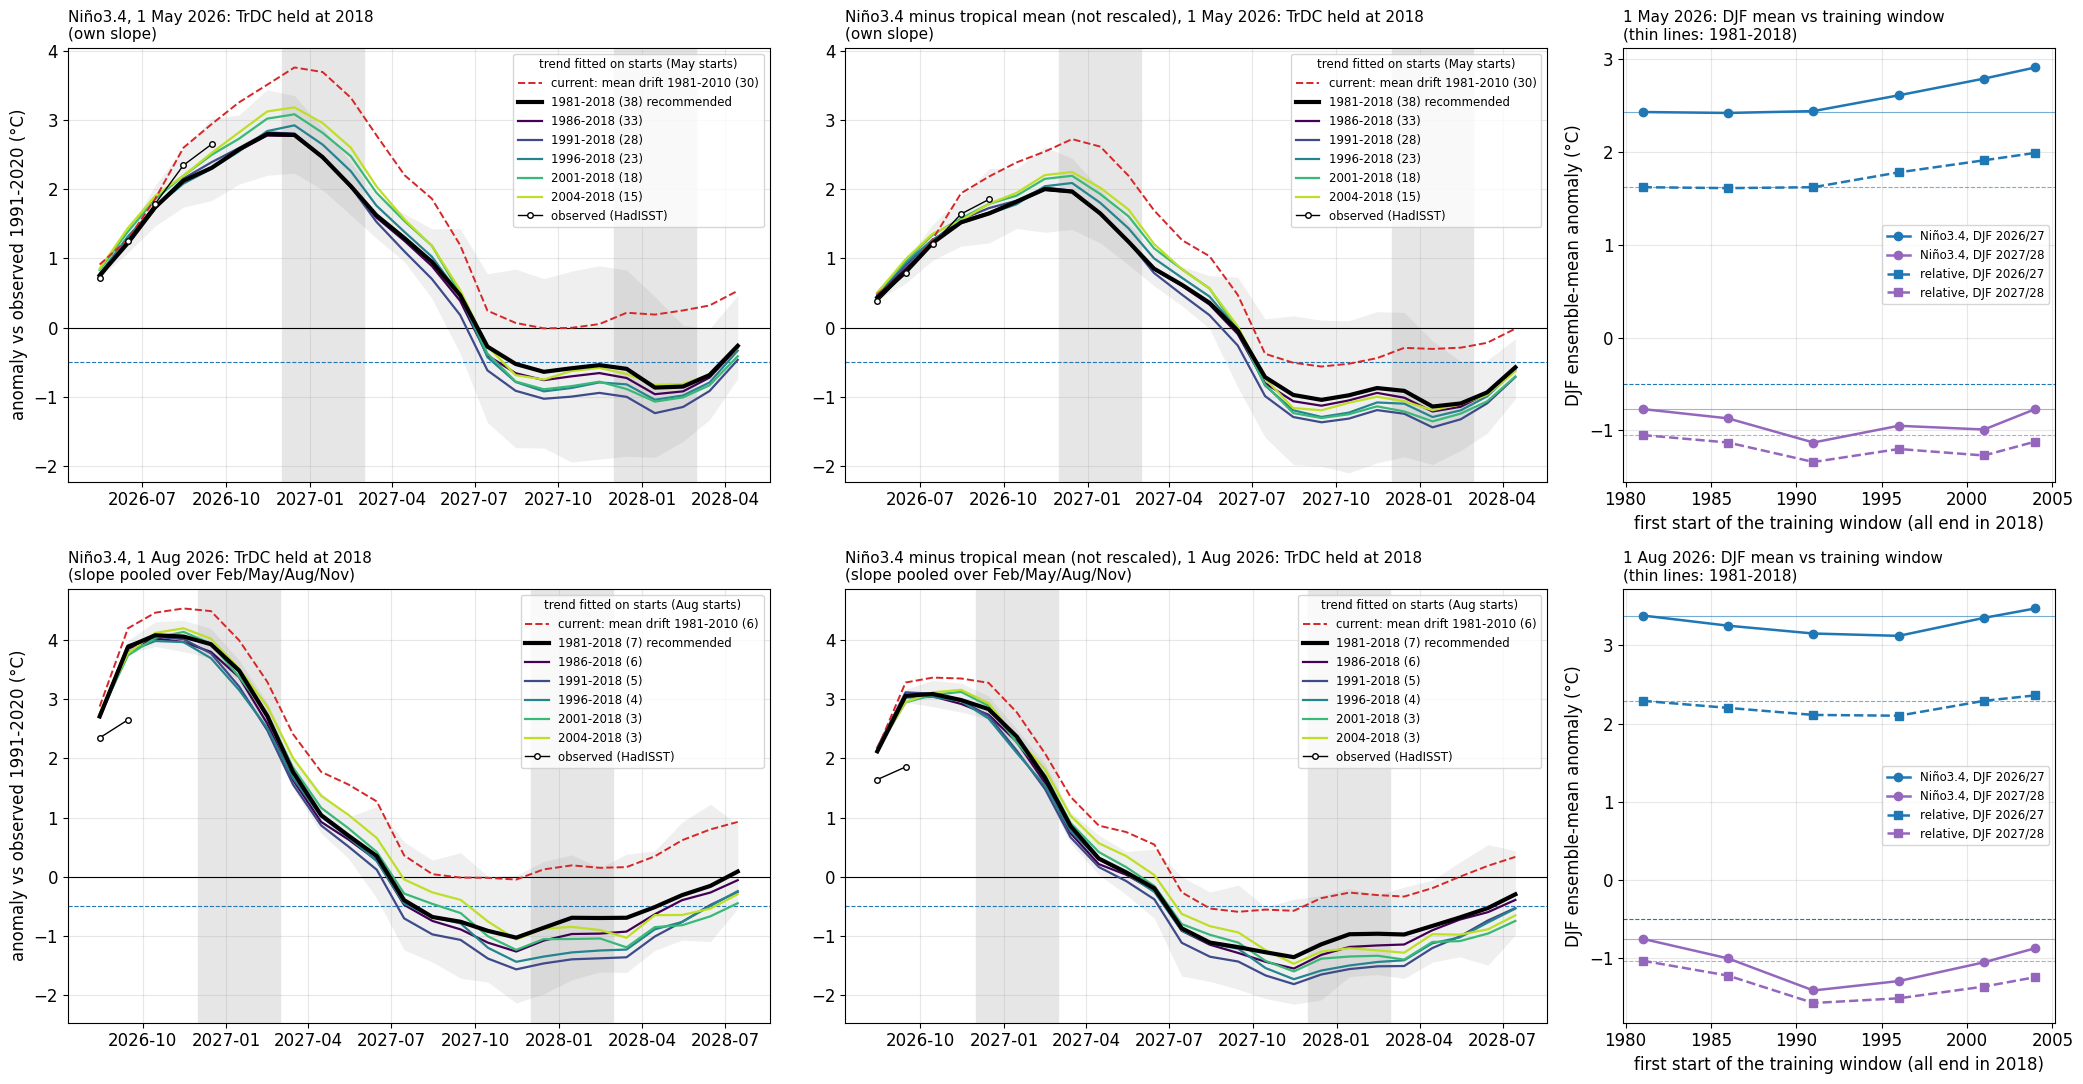

,start,index,method,trend starts,own starts,trend term DJF 2026/27 (°C),DJF 2026/27 mean,P(LN 2026/27),trend term DJF 2027/28 (°C),DJF 2027/28 mean,P(LN 2027/28),P(both)
0,1 May 2026,Nino3.4,T1,1981-2018 (recommended),38,0.98,2.43,0.0,0.80,-0.77,0.70,0.0
1,1 May 2026,Nino3.4,T1,1986-2018,33,0.87,2.42,0.0,0.84,-0.87,0.70,0.0
2,1 May 2026,Nino3.4,T1,1991-2018,28,0.72,2.44,0.0,1.06,-1.13,0.73,0.0
3,1 May 2026,Nino3.4,T1,1996-2018,23,0.34,2.61,0.0,0.62,-0.95,0.70,0.0
4,1 May 2026,Nino3.4,T1,2001-2018,18,0.03,2.79,0.0,0.56,-0.99,0.70,0.0
5,1 May 2026,Nino3.4,T1,2004-2018,15,-0.16,2.91,0.0,0.17,-0.77,0.70,0.0
6,1 May 2026,Relative,T1,1981-2018 (recommended),38,0.75,1.62,0.0,0.60,-1.05,0.73,0.0
7,1 May 2026,Relative,T1,1986-2018,33,0.67,1.61,0.0,0.63,-1.13,0.73,0.0
8,1 May 2026,Relative,T1,1991-2018,28,0.55,1.62,0.0,0.82,-1.34,0.83,0.0
9,1 May 2026,Relative,T1,1996-2018,23,0.24,1.78,0.0,0.48,-1.20,0.83,0.0


,start,index,method,trend starts,own starts,trend term DJF 2026/27 (°C),DJF 2026/27 mean,P(LN 2026/27),trend term DJF 2027/28 (°C),DJF 2027/28 mean,P(LN 2027/28),P(both)
12,1 Aug 2026,Nino3.4,T1p,1981-2018 (recommended),7,0.49,3.38,0.0,0.71,-0.75,0.57,0.0
13,1 Aug 2026,Nino3.4,T1p,1986-2018,6,0.45,3.25,0.0,0.75,-1.00,0.67,0.0
14,1 Aug 2026,Nino3.4,T1p,1991-2018,5,0.44,3.15,0.0,0.88,-1.41,0.87,0.0
15,1 Aug 2026,Nino3.4,T1p,1996-2018,4,0.21,3.12,0.0,0.55,-1.29,0.83,0.0
16,1 Aug 2026,Nino3.4,T1p,2001-2018,3,-0.01,3.35,0.0,0.46,-1.05,0.70,0.0
17,1 Aug 2026,Nino3.4,T1p,2004-2018,3,-0.13,3.47,0.0,0.29,-0.87,0.67,0.0
18,1 Aug 2026,Relative,T1p,1981-2018 (recommended),7,0.37,2.29,0.0,0.53,-1.03,0.83,0.0
19,1 Aug 2026,Relative,T1p,1986-2018,6,0.33,2.20,0.0,0.55,-1.22,0.90,0.0
20,1 Aug 2026,Relative,T1p,1991-2018,5,0.32,2.11,0.0,0.66,-1.57,0.97,0.0
21,1 Aug 2026,Relative,T1p,1996-2018,4,0.15,2.10,0.0,0.42,-1.51,0.90,0.0


In [5]:
tr_colors = ["k"] + list(plt.cm.viridis(np.linspace(0, 0.9, len(TR_BASES) - 1)))
rows = []
fig, axes = plt.subplots(len(STARTS_2026), 3, figsize=(21, 5.5 * len(STARTS_2026)), gridspec_kw={"width_ratios": [1.3, 1.3, 0.8]})
for r_, init in enumerate(STARTS_2026):
    x = [target(YEAR, init, L).to_timestamp() + pd.Timedelta(days=14) for L in range(NLEAD_REF)]
    W = winters(init)
    slope_note = "own slope" if METHOD[init] == "T1" else "slope pooled over Feb/May/Aug/Nov"
    for ax, kind in zip(axes[r_, :2], ("Nino3.4", "Relative")):
        a0, _, n0 = forecast_anomaly(kind, init, "fixed", CURRENT)
        ax.plot(x, a0.mean(0), color="tab:red", lw=1.4, ls="--", zorder=4,
                label=f"current: mean drift {CURRENT[0]}-{CURRENT[1]} ({n0})")
        for win, c in zip(TR_BASES, tr_colors):
            a, term, n = forecast_anomaly(kind, init, METHOD[init], win)
            default = win[0] == YEARS[0]
            ax.plot(x, a.mean(0), color=c, lw=3 if default else 1.6, zorder=5 if default else 3,
                    label=f"{win[0]}-{win[1]} ({n})" + (" recommended" if default else ""))
            if default:
                ax.fill_between(x, *np.percentile(a, [10, 90], axis=0), color="0.5", alpha=0.12, lw=0)
            v = {w: djf(a, f) for w, f in W.items()}
            ln = {w: v[w] <= THRESHOLD for w in v}
            row = {"start": f"1 {INIT_NAME[init]} {YEAR}", "index": kind, "method": METHOD[init],
                   "trend starts": f"{win[0]}-{win[1]}" + (" (recommended)" if default else ""), "first start": win[0],
                   "own starts": n}
            for w in W:
                row.update({f"trend term DJF {w} (°C)": round(float(djf(term, W[w])), 2), f"DJF {w} mean": round(v[w].mean(), 2),
                            f"P(LN {w})": round(ln[w].mean(), 2)})
            row["P(both)"] = round(np.logical_and(*ln.values()).mean(), 2)
            rows.append(row)
        ob = observed_anomaly(kind, init)
        ax.plot(x, ob, "o-", color="k", ms=4, lw=1, mfc="w", zorder=6, label="observed (HadISST)")
        ax.axhline(0, color="k", lw=0.8)
        ax.axhline(THRESHOLD, color="tab:blue", ls="--", lw=0.8)
        for f in W.values():
            ax.axvspan(x[f] - pd.Timedelta(days=14), x[f + 2] + pd.Timedelta(days=14), color="0.9", zorder=0)
        ax.set_title(f"{'Niño3.4' if kind == 'Nino3.4' else 'Niño3.4 minus tropical mean (not rescaled)'}, 1 {INIT_NAME[init]} {YEAR}: "
                     f"TrDC held at {TR_END}\n({slope_note})", loc="left", fontsize=11)
        ax.legend(fontsize=8.5, loc="upper right", title=f"trend fitted on starts ({INIT_NAME[init]} starts)", title_fontsize=8.5)
    axes[r_, 0].set_ylabel(f"anomaly vs observed {OBS_BASE[0]}-{OBS_BASE[1]} (°C)")
    axes[r_, 1].sharey(axes[r_, 0])
    ax = axes[r_, 2]
    p = pd.DataFrame([q for q in rows if q["start"] == f"1 {INIT_NAME[init]} {YEAR}"])
    for kind, ls, mk in (("Nino3.4", "-", "o"), ("Relative", "--", "s")):
        sub = p[p["index"] == kind]
        dflt = sub[sub["first start"] == YEARS[0]].iloc[0]
        for (w, c) in zip(W, ("tab:blue", "tab:purple")):
            ax.plot(sub["first start"], sub[f"DJF {w} mean"], color=c, ls=ls, marker=mk, lw=1.8,
                    label=f"{'Niño3.4' if kind == 'Nino3.4' else 'relative'}, DJF {w}")
            ax.axhline(dflt[f"DJF {w} mean"], color=c, ls=ls, lw=0.8, alpha=0.6)
    ax.axhline(THRESHOLD, color="tab:blue", ls="--", lw=0.8)
    ax.set_xlabel(f"first start of the training window (all end in {TR_END})")
    ax.set_ylabel("DJF ensemble-mean anomaly (°C)")
    ax.set_title(f"1 {INIT_NAME[init]} {YEAR}: DJF mean vs training window\n(thin lines: {YEARS[0]}-{TR_END})", loc="left", fontsize=11)
    ax.legend(fontsize=8.5)
fig.tight_layout()
save(fig, "trdc", "may_aug_2026_by_training_starts")
plt.show()
p_may_aug = pd.DataFrame(rows)
p_may_aug.to_csv(DATA_DIR / "may_aug_2026_la_nina_trdc_by_training_starts.csv", index=False)
with pd.option_context("display.max_columns", 30, "display.width", 250):
    for init in STARTS_2026:
        display(p_may_aug[p_may_aug["start"] == f"1 {INIT_NAME[init]} {YEAR}"].dropna(axis=1, how="all").drop(columns="first start"))

### 2. P(La Niña 2027/28) from the May, Aug and Nov 2026 starts

Winter 2026/27 is the El Niño peak in every member (DJF ensemble mean +2.4 to +3.5 °C), so P(La Niña 2026/27) and
P(La Niña in both winters) are 0 for every correction; the winter that all three 2026 starts forecast is
**2027/28**. Fraction of the 30 members with a Niño3.4 DJF 2027/28 mean ≤ −0.5 °C, for the current mean drift and the
TrDC windows; Nov from `03` (section 3c and the 1981-2010 mean drift of section 3; DJF 2027/28 does not depend on
the year-3 rule). Black lines: ±0.08 sampling uncertainty of a 30-member fraction.

/global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/nov2026_outlook/08_may_aug_2026_trdc/figures/fig_trdc_p_la_nina_2027_28_by_start_and_training_starts.png


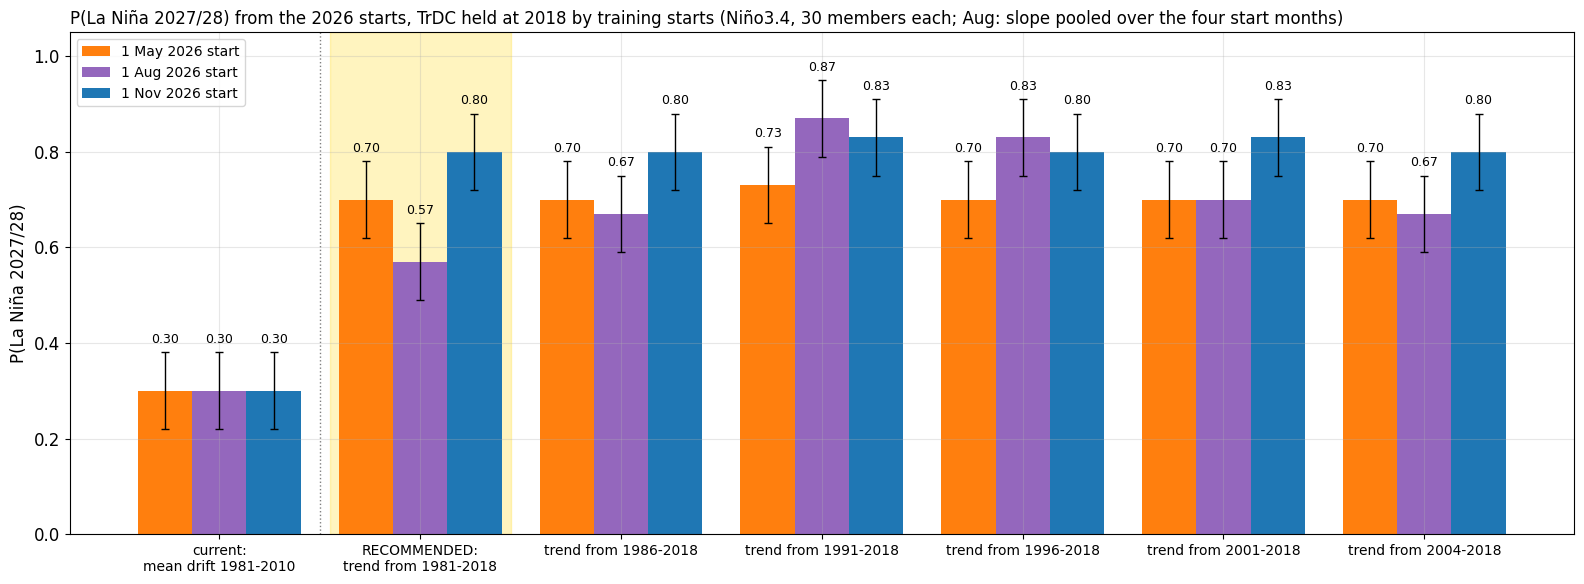

,1 May 2026,1 Aug 2026,1 Nov 2026
current: mean drift 1981-2010,0.30,0.30,0.30
RECOMMENDED: trend from 1981-2018,0.70,0.57,0.80
trend from 1986-2018,0.70,0.67,0.80
trend from 1991-2018,0.73,0.87,0.83
trend from 1996-2018,0.70,0.83,0.80
trend from 2001-2018,0.70,0.70,0.83
trend from 2004-2018,0.70,0.67,0.80


In [6]:
r03 = rc.output_dir("nov2026_outlook/03_drift_trend_and_test", "data")
for f in ("nov2026_la_nina_trdc_by_training_starts.csv", "nov2026_la_nina_by_drift_method.csv"):
    if not (r03 / f).is_file():
        raise FileNotFoundError(f"{r03 / f}: run 03_drift_trend_and_test.ipynb first")
nov_w = pd.read_csv(r03 / "nov2026_la_nina_trdc_by_training_starts.csv")
nov_w = nov_w[nov_w["index"] == "Nino3.4"]
nov_m = pd.read_csv(r03 / "nov2026_la_nina_by_drift_method.csv")
nov_cur = nov_m[(nov_m["index"] == "Nino3.4") & (nov_m["method"] == f"fixed {CURRENT[0]}-{CURRENT[1]}")].iloc[0]

W27 = f"{YEAR + 1}/{(YEAR + 2) % 100:02d}"
cols = {f"1 {INIT_NAME[i]} {YEAR}": {} for i in STARTS_2026} | {f"1 Nov {YEAR}": {}}
labels = [f"current:\nmean drift {CURRENT[0]}-{CURRENT[1]}"] + [
    ("RECOMMENDED:\n" if s == YEARS[0] else "") + f"trend from {s}-{e}" for s, e in TR_BASES]
for init in STARTS_2026:
    a0, _, _ = forecast_anomaly("Nino3.4", init, "fixed", CURRENT)
    key = f"1 {INIT_NAME[init]} {YEAR}"
    cols[key][labels[0]] = float((djf(a0, winters(init)[W27]) <= THRESHOLD).mean())
    sub = p_may_aug[(p_may_aug["index"] == "Nino3.4") & (p_may_aug["start"] == key)]
    for lab, (s, _) in zip(labels[1:], TR_BASES):
        cols[key][lab] = float(sub[sub["first start"] == s][f"P(LN {W27})"].iloc[0])
cols[f"1 Nov {YEAR}"][labels[0]] = float(nov_cur["P(LN 27/28)"])
for lab, (s, e) in zip(labels[1:], TR_BASES):
    cols[f"1 Nov {YEAR}"][lab] = float(nov_w[nov_w["trend starts"].str.startswith(f"{s}-{e}")]["P(LN 27/28)"].iloc[0])
p27 = pd.DataFrame(cols).reindex(labels)

fig, ax = plt.subplots(figsize=(16, 6))
xb = np.arange(len(p27))
rec = labels.index(next(l for l in labels if l.startswith("RECOMMENDED")))
ax.axvspan(rec - 0.45, rec + 0.45, color="gold", alpha=0.25, zorder=0)
for k, (col, c) in enumerate(zip(p27.columns, ["tab:orange", "tab:purple", "tab:blue"])):
    bars = ax.bar(xb + (k - 1) * 0.27, p27[col], 0.27, color=c, label=f"{col} start", yerr=0.08, capsize=3, error_kw={"lw": 1})
    for i, b_ in enumerate(bars):
        ax.text(b_.get_x() + b_.get_width() / 2, p27[col].iloc[i] + 0.1, f"{p27[col].iloc[i]:.2f}", ha="center", fontsize=9)
ax.axvline(0.5, color="0.5", lw=1, ls=":")
ax.set_xticks(xb, p27.index, fontsize=10)
ax.set_ylim(0, 1.05)
ax.set_ylabel(f"P(La Niña {W27})")
ax.set_title(f"P(La Niña {W27}) from the 2026 starts, TrDC held at {TR_END} by training starts "
             "(Niño3.4, 30 members each; Aug: slope pooled over the four start months)", loc="left", fontsize=12)
ax.legend(fontsize=10, loc="upper left")
fig.tight_layout()
save(fig, "trdc", "p_la_nina_2027_28_by_start_and_training_starts")
plt.show()
p27.index = p27.index.str.replace("\n", " ")
p27.to_csv(DATA_DIR / "p_la_nina_2027_28_by_start_and_training_starts.csv", index_label="construction")
display(p27)

### Findings

(filled in after the first run)